**Projet no. 3 :** Implanter la méthode du gradient et du gradient stochastique pour le SVM en s'appuyant sur le blog (lecture 4 d'EE227C). Étudier numériquement l'effet de la longueur du pas sur la convergence et l'effet de la taille du mini-batch. Reproduire avec mon algorithme les expériences de la page du blog.

Ce notebook contient aussi les deux sections suivantes de la même lecture, *Sparse Inverse Covariance Estimation* et *Gradient madness*, que j'ai lues et commentées (sans expérience supplémentaire).

**sources du cours que j'utilise :**
 - notes EE227C (chap. 2 « Gradient method », chap. 3 « Strong convexity », chap. 10 « Stochastic optimization » avec la déf. 10.3 du SVM p. 54, chap. 15 « Fenchel duality » § 15.2 et exemple 15.6 « Linear SVM » p. 83) ;
 - notre cours (SVM et dualité pdf p. 154-158, sous-gradient pdf p. 147, méthode proximale pdf p. 120-123, gradient stochastique pdf p. 118) ;
 - slides d'optimisation (mini-batch p. 24-26).



## Préparation (imports, fonction de tracé et descente de gradient du notebook d'origine)

In [4]:

%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

np.random.seed(1337)

kwargs = {'linewidth': 3.5}
font = {'weight': 'normal', 'size': 24}
matplotlib.rc('font', **font)
 # Courbe d'erreur par itération (échelle log : une droite = convergence géométrique).
def error_plot(ys, yscale='log'):
    plt.figure(figsize=(8, 8))
    plt.xlabel('Step')
    plt.ylabel('Error')
    plt.yscale(yscale)
    plt.plot(range(len(ys)), ys, **kwargs)

In [5]:
# Descente de gradient projetée : x_{k+1} = Proj( x_k - s_k * grad(x_k) ). `steps` = liste des pas ; nombre d'itérations = len(steps).
# Ici on lui passera un SOUS-gradient (la perte charnière n'est pas dérivable) : c'est la méthode du sous-gradient.
# Aucun critère d'arrêt : le budget est fixé à l'avance.
def gradient_descent(init, steps, grad, proj=lambda x: x):
    """Projected gradient descent.

    Inputs:
        initial: starting point
        steps: list of scalar step sizes
        grad: function mapping points to gradients
        proj (optional): function mapping points to points

    Returns:
        List of all points computed by projected gradient descent.
    """
    xs = [init]
    for step in steps:
        xs.append(proj(xs[-1] - step * grad(xs[-1])))
    return xs

### Ma boîte à outils pour les expériences
Sous-gradient **correct** (moyenne), gradient stochastique par mini-batch, et **SDCA** (méthode duale, mise à jour exacte par coordonnée). Générateur aléatoire local : la suite de nombres aléatoires du notebook d'origine n'est pas perturbée.

In [6]:
import numpy as np


def make_data(seed, m=1000, n=100, m_test=10000):
    """Donnees du notebook: deux classes gaussiennes N(+0.1, I) et N(-0.1, I) (moyennes +-0.1 sur toutes les coordonnees)."""
    rng = np.random.default_rng(seed)
    def gen(mm):
        A = np.vstack([rng.normal(0.1, 1, (mm // 2, n)), rng.normal(-0.1, 1, (mm // 2, n))])
        y = np.hstack([np.ones(mm // 2), -np.ones(mm // 2)])
        return A, y
    A, y = gen(m)
    At, yt = gen(m_test)
    return A, y, At, yt, rng


def svm_obj(A, y, w, alpha):
    return np.mean(np.maximum(0.0, 1.0 - y * (A @ w))) + 0.5 * alpha * (w @ w)


def accuracy(A, y, w):
    return float(np.mean(y * (A @ w) > 0))


def subgrad(A, y, w, alpha, idx=None):
    """Sous-gradient de P(w) (version MOYENNE, coherente avec l'objectif). idx : indices d'un mini-batch."""
    if idx is not None:
        A, y = A[idx], y[idx]
    z = y * (A @ w)
    act = (z < 1.0)
    return -(A[act].T @ y[act]) / len(y) + alpha * w


def subgrad_notebook(A, y, w, alpha):
    """Sous-gradient TEL QUE DANS LE NOTEBOOK : somme (et non moyenne) sur les m exemples -> m fois trop grand pour la partie perte."""
    z = y * (A @ w)
    act = (z < 1.0)
    return -(A[act].T @ y[act]) + alpha * w


def run_subgradient(A, y, alpha, w0, n_iter, step, grad=subgrad, At=None, yt=None, eval_every=10, project_R=None):
    """Sous-gradient complet. step : float ou callable k -> pas. Renvoie w final, f a chaque iteration, iteres moyennes."""
    w = w0.copy()
    fs = [svm_obj(A, y, w, alpha)]
    accs = [(0, accuracy(A, y, w), accuracy(At, yt, w) if At is not None else np.nan)]
    wsum = np.zeros_like(w); half = n_iter // 2; cnt = 0
    for k in range(n_iter):
        s = step(k) if callable(step) else step
        w = w - s * grad(A, y, w, alpha)
        if project_R is not None:
            nrm = np.linalg.norm(w)
            if nrm > project_R: w *= project_R / nrm
        fs.append(svm_obj(A, y, w, alpha))
        if k >= half: wsum += w; cnt += 1
        if (k + 1) % eval_every == 0:
            accs.append((k + 1, accuracy(A, y, w), accuracy(At, yt, w) if At is not None else np.nan))
    return w, np.array(fs), wsum / max(cnt, 1), np.array(accs)


def run_sgd(A, y, alpha, w0, n_epochs, batch, step, rng, project_R=None):
    """Sous-gradient stochastique par mini-batch (tirage sans remise a chaque iteration). 1 epoque = m/batch iterations."""
    m = A.shape[0]
    w = w0.copy(); k = 0
    ipe = max(m // batch, 1)
    fs = [svm_obj(A, y, w, alpha)]
    for _ in range(n_epochs):
        for _ in range(ipe):
            idx = rng.choice(m, size=batch, replace=False) if batch < m else None
            s = step(k) if callable(step) else step
            w = w - s * subgrad(A, y, w, alpha, idx)
            if project_R is not None:
                nrm = np.linalg.norm(w)
                if nrm > project_R: w *= project_R / nrm
            k += 1
        fs.append(svm_obj(A, y, w, alpha))
    return w, np.array(fs)


def sdca(A, y, alpha, n_epochs, rng, tol=None):
    """Stochastic dual coordinate ascent pour le SVM sans biais (mise a jour coordonnee exacte, forme close).
    Primal P(w), dual D(a) = (1/m) sum a_i - (alpha/2)||w||^2 avec w = (1/(alpha m)) sum a_i y_i x_i, a_i dans [0,1].
    Renvoie w, a, historique (primal, ecart de dualite) a chaque epoque."""
    m, n = A.shape
    a = np.zeros(m); w = np.zeros(n)
    sq = np.einsum('ij,ij->i', A, A)
    hist = []
    for ep in range(n_epochs):
        for i in rng.permutation(m):
            da = np.clip((1.0 - y[i] * (A[i] @ w)) * alpha * m / sq[i] + a[i], 0.0, 1.0) - a[i]
            if da != 0.0:
                a[i] += da
                w += da * y[i] * A[i] / (alpha * m)
        P = svm_obj(A, y, w, alpha)
        D = a.mean() - 0.5 * alpha * (w @ w)
        hist.append((P, P - D))
        if tol is not None and P - D < tol:
            break
    return w, a, np.array(hist)


import time
import pandas as pd
from sklearn.svm import LinearSVC

<a id="svm"></a>
## Support Vector Machines

In a linear classification problem, we're given $m$ labeled points $(a_i, y_i)$ and we wish to find a hyperplane given by a point $x$ that separates them so that

* $\langle a_i, x\rangle \ge 1$ when $y_i=1$, and
* $\langle a_i, x\rangle \le -1$ when $y_i = -1$

The smaller the norm $\|x\|$ the larger the *margin* between positive and negative instances. Therefore, it makes sense to throw in a regularizer that penalizes large norms. This leads to the objective.

<p>
$$\frac 1m \sum_{i=1}^m \max\{1-y_i(a_i^\top x), 0\} + \frac{\alpha}2\|x\|^2$$
</p>

> **Ce que j'ai compris du problème :** On a m = 1000 points (a_i, y_i) avec y_i = ±1 en dimension n = 100 et on cherche un hyperplan x ∈ ℝ¹⁰⁰ (sans biais) qui sépare les deux classes. Objectif : minimiser f(x) = (1/m) Σ max(0, 1 − y_i⟨a_i, x⟩) + (α/2)‖x‖². Les variables de décision sont les 100 coefficients de x ; il n'y a pas de contrainte.

> **Nature du problème.** La perte charnière est **convexe mais non dérivable** (un coude en 1). La pénalité (α/2)‖x‖² est **α-fortement convexe**. L'objectif est donc convexe, non lisse, et **fortement convexe** : le minimiseur existe et est unique. C'est une différence importante avec le LASSO (non fortement convexe).


> **Lien avec le cours.** Notes EE227C, déf. 10.3 (p. 54) : même objectif avec une pénalité λ‖w‖² (donc λ = α/2). Les notes remarquent aussi que le Perceptron revient à appliquer la méthode du sous-gradient à cet objectif. Cours (pdf p. 154-158) : le SVM par la **dualité**, avec biais b et contrainte yᵀα = 0 ; ici il n'y a pas de biais, donc pas de contrainte d'égalité (seulement des bornes 0 ≤ a_i ≤ 1 sur les variables duales, voir SDCA plus bas).


> **Pourquoi optimiser ?** La marge géométrique vaut 1/‖x‖ quand les données sont séparables : minimiser ‖x‖ maximise la marge ; la perte charnière pénalise les points mal classés ou trop proches de la frontière.

In [7]:
# Perte charnière max(1 - z, 0) avec z = y_i <a_i, x> (la « marge » du point i), puis objectif SVM.
# Critique : np.diag(y).dot(A.dot(x)) construit une matrice m x m à chaque appel : O(m^2) en mémoire et en temps.
# L'écriture y * (A @ x) donne le même résultat en O(m n). La variable m est inutilisée.
def hinge_loss(z):
    return np.maximum(1.-z, np.zeros(z.shape))

def svm_objective(A, y, x, alpha=0.1):
    """SVM objective."""
    m, _ = A.shape
    return np.mean(hinge_loss(np.diag(y).dot(A.dot(x))))+(alpha/2)*x.dot(x)

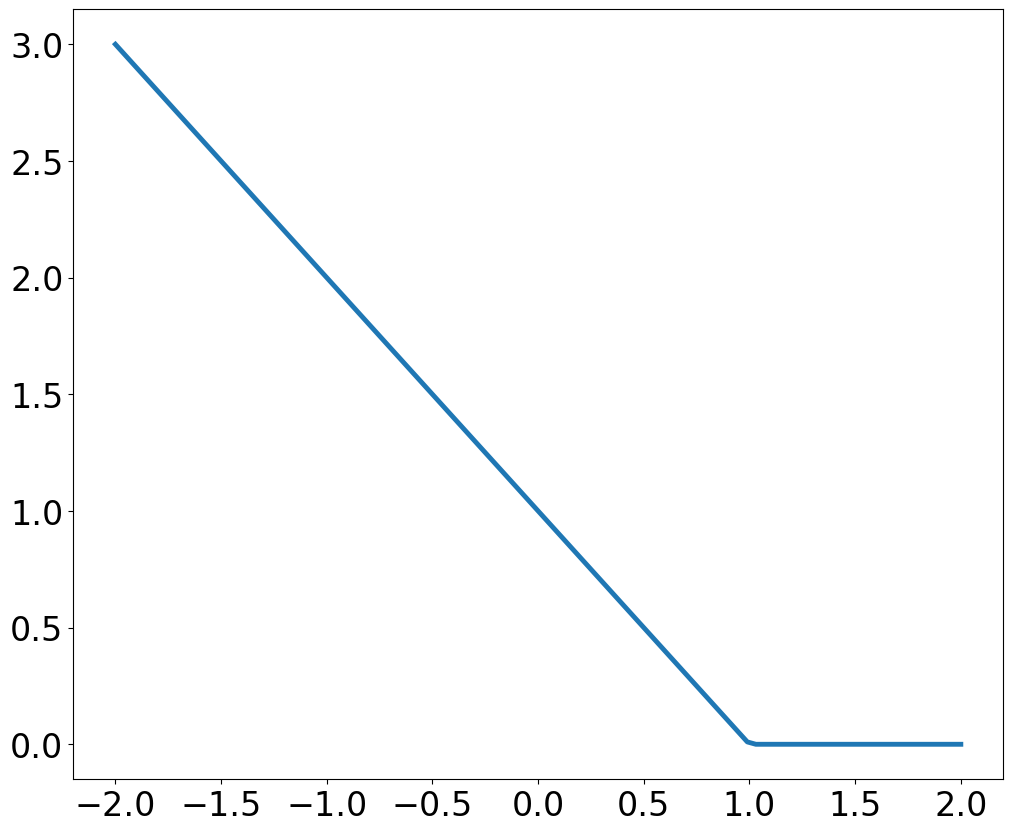

In [8]:
z = np.linspace(-2, 2, 100)
plt.figure(figsize=(12,10))
plt.plot(z, hinge_loss(z), **kwargs)

> **Interprétation de la figure.** La perte est nulle dès que z ≥ 1 (le point est bien classé *avec marge*), puis augmente linéairement quand z diminue. Seuls les points avec z < 1 (mal classés ou dans la marge, les « vecteurs supports » en pratique) contribuent au sous-gradient. Le coude en z = 1 est le point de non-dérivabilité.

In [9]:
# Sous-gradient de la perte charnière : -1 si z < 1, 0 sinon (en z = 1 on choisit 0, valeur valide dans [-1, 0]).
# Attention, erreur d'échelle : l'objectif (cellule précédente) contient une MOYENNE (1/m) sum, mais ici g1.dot(g2) calcule la SOMME sum_i (-1[z_i<1]) y_i a_i, sans diviser par m.
# La partie « perte » du sous-gradient est donc m fois trop grande par rapport à l'objectif affiché. Voir la cellule de vérification juste après.
def hinge_subgradient(z):
    g = np.zeros(z.shape)
    g[z < 1] = -1.
    return g

def svm_subgradient(A, y, x, alpha=0.1):
    g1 = hinge_subgradient(np.diag(y).dot(A.dot(x)))
    g2 = np.diag(y).dot(A)
    return g1.dot(g2) + alpha*x

In [10]:
# j'ai rajouté cette cellule : Vérification de l'échelle du sous-gradient du notebook par différences finies (la fonction est dérivable presque partout)
rng_chk = np.random.default_rng(0)
m_, n_ = 1000, 100
A_chk = np.vstack([rng_chk.normal(0.1, 1, (m_ // 2, n_)), rng_chk.normal(-0.1, 1, (m_ // 2, n_))]); y_chk = np.hstack([np.ones(m_ // 2), -np.ones(m_ // 2)])
w_chk = rng_chk.normal(0, 1, n_); d_chk = rng_chk.normal(0, 1, n_); d_chk /= np.linalg.norm(d_chk); h_ = 1e-6; a_chk = 0.05
fd = (svm_obj(A_chk, y_chk, w_chk + h_ * d_chk, a_chk) - svm_obj(A_chk, y_chk, w_chk - h_ * d_chk, a_chk)) / (2 * h_)   # derivee directionnelle de l'objectif
print("derivee directionnelle de l'objectif (differences finies) : %.4f" % fd)
print("<sous-gradient du notebook, d>                            : %.4f   (rapport = %.0f)" % (subgrad_notebook(A_chk, y_chk, w_chk, a_chk) @ d_chk, (subgrad_notebook(A_chk, y_chk, w_chk, a_chk) @ d_chk) / fd))
print("<sous-gradient corrige (moyenne), d>                      : %.4f" % (subgrad(A_chk, y_chk, w_chk, a_chk) @ d_chk))

derivee directionnelle de l'objectif (differences finies) : 0.0328
<sous-gradient du notebook, d>                            : 11.0727   (rapport = 337)
<sous-gradient corrige (moyenne), d>                      : 0.0328


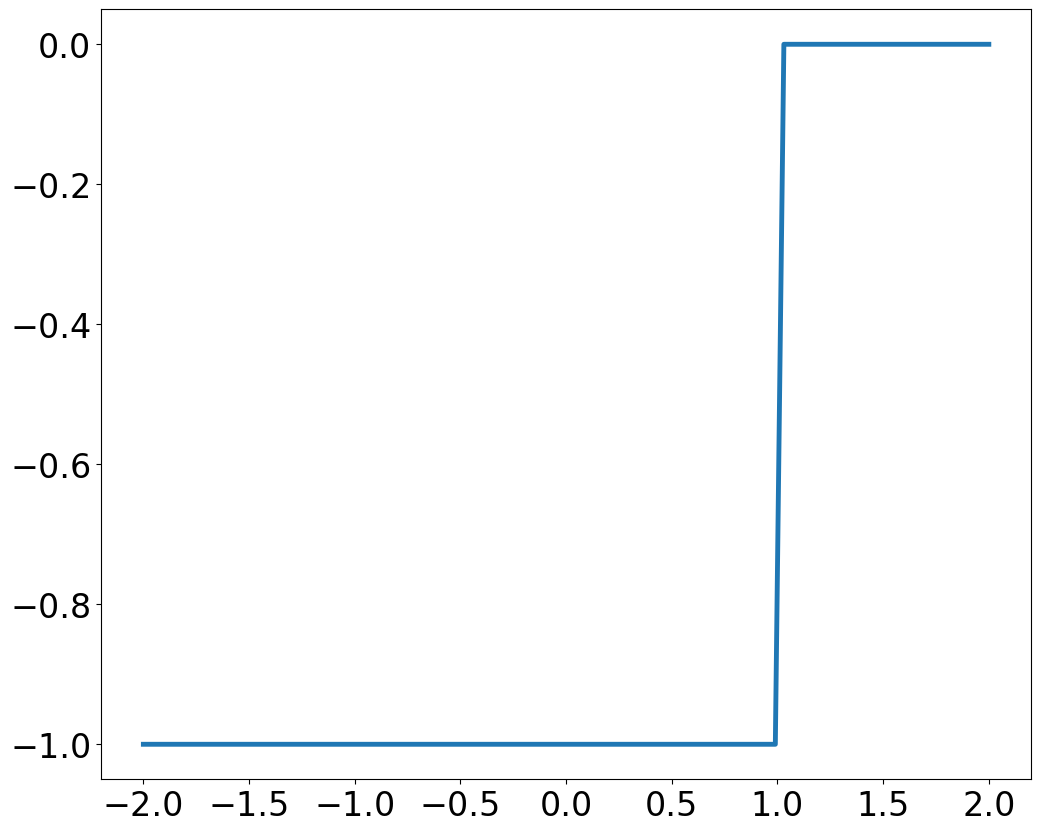

In [11]:
plt.figure(figsize=(12,10))
plt.plot(z, hinge_subgradient(z), **kwargs)

> **Ce que j'ai compris :**
Le sous-gradient de la perte est une fonction **en escalier** (−1 puis 0) : il saute brutalement en z = 1. Contrairement à un gradient, il n'est pas continu, donc il peut changer d'un coup d'une itération à l'autre.


> **Critique (importante).** Le sous-gradient du notebook est une **somme** alors que l'objectif est une **moyenne** : la partie « perte » est exactement **m = 1000 fois trop grande** (le facteur 1/m a été oublié). La cellule de vérification le confirme par différences finies : le rapport mesuré sur une direction donnée dépend du point (ici de l'ordre de plusieurs centaines), car la partie αx n'est pas multipliée. Ce n'est pas un détail : tout se passe comme si le notebook minimisait une fonction où la régularisation vaut α/m = 5·10⁻⁵ au lieu de 0,05, avec un pas effectif de 0,01 × 1000 = 10. L'effet sur les résultats est mesuré plus bas.

In [12]:
# Données : deux gaussiennes N(+0.1, I) et N(-0.1, I) en dimension 100 (m = 1000 points, classes équilibrées).
# Les classes se recouvrent fortement : elles ne sont PAS séparables. L'écart entre les moyennes est faible devant l'écart-type 1.
# Départ aléatoire N(0, I) (norme ~10), pas CONSTANT 0.01, 100 itérations seulement, alpha = 0.05.
# Attention : (a) sous-gradient du notebook (somme au lieu de moyenne) ; (b) un seul point de départ, une seule instance ; (c) aucun critère d'arrêt ;
# (d) l'optimisation utilise alpha = 0.05 alors que la courbe tracée à la cellule suivante utilise svm_objective(A, y, x) avec alpha PAR DÉFAUT = 0.1.
m, n = 1000, 100
A = np.vstack([np.random.normal(0.1, 1, (m//2, n)),
               np.random.normal(-0.1, 1, (m//2, n))])
y = np.hstack([np.ones(m//2), -1.*np.ones(m//2)])
x0 = np.random.normal(0, 1, n)
xs = gradient_descent(x0, [0.01]*100,
                      lambda x: svm_subgradient(A, y, x, 0.05))

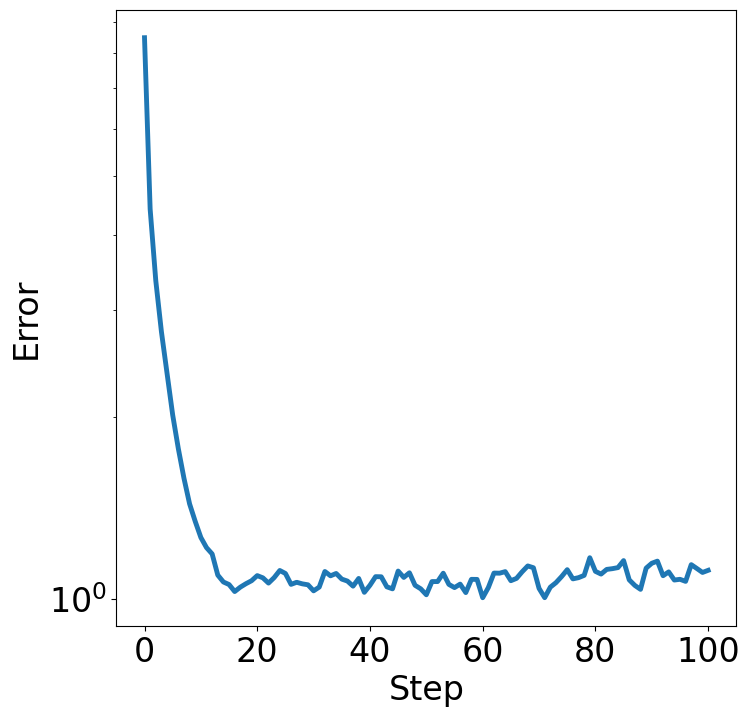

In [13]:
# Attention, incohérence de alpha : svm_objective(A, y, x) est appelée sans alpha, donc avec alpha = 0.1 (valeur par défaut de la cellule 50),
# alors que le sous-gradient a été calculé avec alpha = 0.05. La courbe tracée n'est PAS l'objectif qui est minimisé.
error_plot([svm_objective(A, y, x) for x in xs])

In [14]:
# j'ai rajouté cette cellule : Que fait réellement la courbe de la cellule précédente ? On compare à la vraie solution (SDCA, vérifiée contre scikit-learn)
alpha_ = 0.05
w_star, a_star, h_star = sdca(A, y, alpha_, 5000, np.random.default_rng(0), tol=1e-12)
f_star = h_star[-1, 0]
sk_ = LinearSVC(loss='hinge', fit_intercept=False, C=1 / (alpha_ * len(y)), tol=1e-10, max_iter=1000000, dual=True).fit(A, y)
print("f* (SDCA) = %.8f  | f (scikit-learn) = %.8f  | ecart sur w : %.1e | ecart de dualite SDCA = %.1e" % (f_star, svm_obj(A, y, sk_.coef_.ravel(), alpha_), np.linalg.norm(w_star - sk_.coef_.ravel()), h_star[-1, 1]))
print("f(w_0) = %.2f ; f(x_100 du notebook) = %.4f ; f(x_100) - f* = %.4f" % (svm_obj(A, y, xs[0], alpha_), svm_obj(A, y, xs[-1], alpha_), svm_obj(A, y, xs[-1], alpha_) - f_star))
F_nb = np.array([svm_obj(A, y, x, alpha_) for x in xs])
print("min_k f(x_k) = %.4f atteint a k = %d" % (F_nb.min(), int(F_nb.argmin())))
# la meme experience avec le sous-gradient CORRIGE (moyenne) a pas 0.01 et a pas 0.01*m (pas effectif equivalent)
wc, Fc, _, _ = run_subgradient(A, y, alpha_, xs[0], 100, 0.01, grad=subgrad)
wc2, Fc2, _, _ = run_subgradient(A, y, alpha_, xs[0], 100, 0.01 * len(y), grad=subgrad)
print("f(x_100) - f*  : notebook = %.4f | corrige, pas 0.01 = %.4f | corrige, pas 0.01*m = 10 = %.4f" % (F_nb[-1] - f_star, Fc[-1] - f_star, Fc2[-1] - f_star))
print("alpha effectif de la version du notebook : alpha/m = %.1e" % (alpha_ / len(y)))
print("Objectif trace par le notebook (svm_objective, alpha PAR DEFAUT = 0.1) : f(x_0) = %.2f, f(x_100) = %.4f | avec alpha = 0.05 (celui de l'optimisation) : f(x_0) = %.2f, f(x_100) = %.4f" % (svm_objective(A, y, xs[0]), svm_objective(A, y, xs[-1]), svm_obj(A, y, xs[0], 0.05), svm_obj(A, y, xs[-1], 0.05)))
print("||x_100|| (notebook) = %.2f  ;  ||w*|| (vraie solution, alpha=0.05) = %.2f" % (np.linalg.norm(xs[-1]), np.linalg.norm(w_star)))

f* (SDCA) = 0.36063705  | f (scikit-learn) = 0.36063705  | ecart sur w : 2.7e-10 | ecart de dualite SDCA = 9.9e-13
f(w_0) = 6.24 ; f(x_100 du notebook) = 0.7922 ; f(x_100) - f* = 0.4315
min_k f(x_k) = 0.7161 atteint a k = 71
f(x_100) - f*  : notebook = 0.4315 | corrige, pas 0.01 = 4.9358 | corrige, pas 0.01*m = 10 = 0.8927
alpha effectif de la version du notebook : alpha/m = 5.0e-05
Objectif trace par le notebook (svm_objective, alpha PAR DEFAUT = 0.1) : f(x_0) = 8.48, f(x_100) = 1.1138 | avec alpha = 0.05 (celui de l'optimisation) : f(x_0) = 6.24, f(x_100) = 0.7922
||x_100|| (notebook) = 3.59  ;  ||w*|| (vraie solution, alpha=0.05) = 1.30


> **Résultats mesurés.** SDCA et scikit-learn donnent la même solution (écart de 3·10⁻¹⁰ sur w) : f\* = 0,3606. Sur la trajectoire du notebook : f(x₁₀₀) = 0,79 avec α = 0,05, soit f − f\* = **0,43** (plus de deux fois l'optimum), avec un minimum de 0,72 atteint à l'itération 71 puis une légère remontée. La norme de l'itéré final est **3,6** alors que la vraie solution a une norme de **1,3**.

> **Deux problèmes se cumulent dans la cellule d'origine.** (1) *Erreur d'échelle* : le sous-gradient est une somme et non une moyenne. La mise à jour du notebook, w ← w − 0,01·(Σ… + αw), est identique à w ← w − 10·[(1/m)Σ… + (α/m)w] : tout se passe comme si on minimisait le SVM avec une régularisation de **α/m = 5·10⁻⁵** (quasiment aucune) et un pas de **10**. D'où une norme trop grande et une courbe qui plafonne en oscillant. (2) *Incohérence d'α* : la courbe est tracée avec `svm_objective(A, y, x)`, donc α = 0,1 par défaut (f passe de 8,48 à 1,11), alors que l'optimisation utilise α = 0,05 (6,24 à 0,79). La figure du notebook ne montre donc pas l'objectif qui est minimisé.

> **Pourquoi le pas 0,01 « marche » dans le notebook.** Avec le sous-gradient correct et le même pas 0,01, la méthode ne bouge presque pas en 100 itérations (f − f\* = 4,9) : le pas du notebook n'est adapté que grâce à l'erreur d'échelle. Cela illustre qu'un réglage peut sembler bon pour de mauvaises raisons.

>  On ne valide pas une implémentation par l'allure d'une courbe : il faut une référence indépendante (ici SDCA et scikit-learn qui coïncident) et des vérifications (différences finies, cohérence d'α).

Let's see if averaging out the solutions gives us an improved function value.

In [15]:
# Moyenne de TOUS les itérés, y compris le point de départ aléatoire x_0 (norme ~10) et les premières itérations, très loin de la solution.
# Critique : en pratique on moyenne seulement la seconde moitié des itérés (« suffix averaging »), pas depuis le début.
# Attention : svm_objective est de nouveau appelée avec alpha = 0.1 (défaut), alors que l'optimisation utilise 0.05.
xavg = 0.0
for x in xs:
    xavg += x
svm_objective(A, y, xs[-1]), svm_objective(A, y, xavg/len(xs))

(np.float64(1.1138196589759082), np.float64(0.9494869026512647))

In [16]:
# j'ai rajouté cette cellule : Moyenne de tous les iterés (comme le notebook) vs moyenne de la seconde moitié, sur la meme trajectoire
x_all = np.mean(xs, axis=0); x_half = np.mean(xs[len(xs) // 2:], axis=0)
print("f(dernier) - f* = %.4f | f(moyenne de tous) - f* = %.4f | f(moyenne 2e moitie) - f* = %.4f" % (svm_obj(A, y, xs[-1], alpha_) - f_star, svm_obj(A, y, x_all, alpha_) - f_star, svm_obj(A, y, x_half, alpha_) - f_star))

f(dernier) - f* = 0.4315 | f(moyenne de tous) - f* = 0.2894 | f(moyenne 2e moitie) - f* = 0.2643


> **Résultats mesurés** (sur la trajectoire du notebook, α = 0,05). f − f\* vaut 0,43 pour le dernier itéré, 0,29 pour la moyenne de tous les itérés (comme le notebook) et 0,26 pour la moyenne de la seconde moitié.


> **Interprétation.** Ici la moyenne **améliore** la valeur de l'objectif parce que les derniers itérés oscillent autour de la solution (pas effectif trop grand) : en moyennant, on annule en partie les oscillations. C'est une technique classique pour le sous-gradient ( moyennage de Polyak-Ruppert). Mais on verra en E2 que ce n'est pas un gain systématique : quand les itérés convergent encore régulièrement, la moyenne inclut des points plus anciens et moins bons, et peut être pire que le dernier itéré.


> **Critique.** Le notebook moyenne *tous* les itérés, y compris le point de départ aléatoire de norme ≈ 10 ; le moyennage de la seconde moitié est plus raisonnable. Et la comparaison du notebook utilise α = 0,1 alors que l'optimisation utilise 0,05.

:We can also look at the accuracy of our linear model for predicting the labels. From how we defined the data, we can see that the all ones vector is the highest accuracy classifier in the limit of infinite data (very large $m$). For a finite data set, the accuracy could be even higher due to random fluctuations.

In [17]:
# Précision = proportion de points dont la marge y<a,x> est strictement positive (bien classés).
# Attention : calculée sur les données d'ENTRAÎNEMENT, celles qui servent à optimiser. Elle ne mesure pas la capacité à généraliser.
def accuracy(A, y, x):
    return np.mean(np.diag(y).dot(A.dot(x))>0)

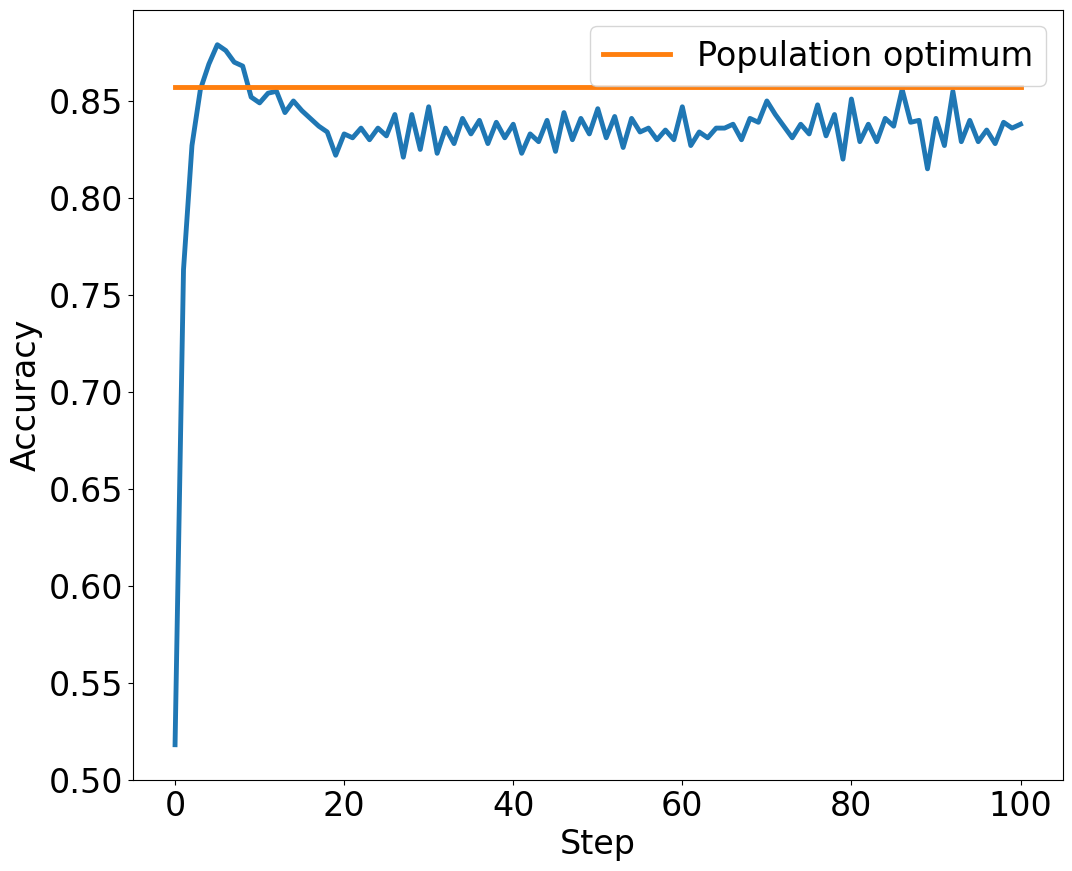

In [18]:
plt.figure(figsize=(12,10))
plt.ylabel('Accuracy')
plt.xlabel('Step')
plt.plot(range(len(xs)), [accuracy(A, y, x) for x in xs], **kwargs)
plt.plot(range(len(xs)), [accuracy(A, y, np.ones(n))]*len(xs),
        label='Population optimum', **kwargs)
_ = plt.legend()

Precision (train / test)
  w* exact (SDCA)           : 0.866 / 0.822
  vecteur de uns (notebook) : 0.857 / 0.843
  notebook, k=100           : 0.838 / 0.803 ; max test 0.814 a k=6


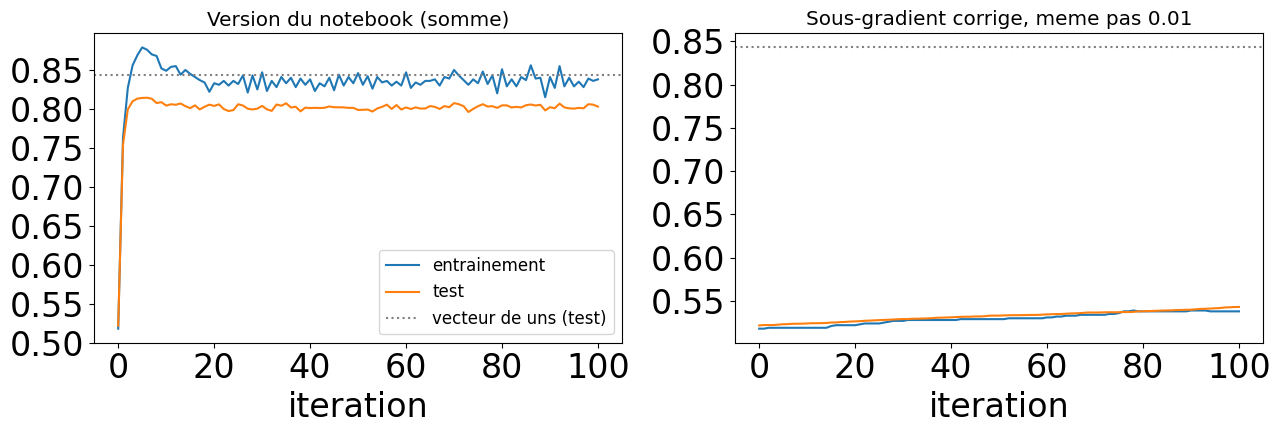

In [19]:
# j'ai rajouté cette cellule : Précision d'entraînement ET de test (10 000 nouveaux points de la même loi), version du notebook vs version corrigée
rng_t = np.random.default_rng(123)
At_ = np.vstack([rng_t.normal(0.1, 1, (5000, 100)), rng_t.normal(-0.1, 1, (5000, 100))]); yt_ = np.hstack([np.ones(5000), -np.ones(5000)])
_, _, _, acc_nb = run_subgradient(A, y, alpha_, xs[0], 100, 0.01, grad=subgrad_notebook, At=At_, yt=yt_, eval_every=1)
_, _, _, acc_ok = run_subgradient(A, y, alpha_, xs[0], 100, 0.01, grad=subgrad, At=At_, yt=yt_, eval_every=1)
print("Precision (train / test)")
print("  w* exact (SDCA)           : %.3f / %.3f" % (accuracy(A, y, w_star), accuracy(At_, yt_, w_star)))
print("  vecteur de uns (notebook) : %.3f / %.3f" % (accuracy(A, y, np.ones(100)), accuracy(At_, yt_, np.ones(100))))
print("  notebook, k=100           : %.3f / %.3f ; max test %.3f a k=%d" % (acc_nb[-1, 1], acc_nb[-1, 2], acc_nb[:, 2].max(), acc_nb[acc_nb[:, 2].argmax(), 0]))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
with plt.rc_context({'font.size': 12}):
    ax[0].plot(acc_nb[:, 0], acc_nb[:, 1], label='entrainement'); ax[0].plot(acc_nb[:, 0], acc_nb[:, 2], label='test'); ax[0].axhline(accuracy(At_, yt_, np.ones(100)), color='gray', ls=':', label='vecteur de uns (test)')
    ax[0].set_title('Version du notebook (somme)'); ax[0].set_xlabel('iteration'); ax[0].legend()
    ax[1].plot(acc_ok[:, 0], acc_ok[:, 1], label='entrainement'); ax[1].plot(acc_ok[:, 0], acc_ok[:, 2], label='test'); ax[1].axhline(accuracy(At_, yt_, np.ones(100)), color='gray', ls=':')
    ax[1].set_title('Sous-gradient corrige, meme pas 0.01'); ax[1].set_xlabel('iteration'); plt.tight_layout(); plt.show()

> **Résultats mesurés** (précision d'entraînement / de test sur 10 000 nouveaux points). Solution exacte w\* : **0,866 / 0,822**. Vecteur de uns : 0,857 / 0,843. Itéré final du notebook (k = 100) : 0,838 / 0,803, avec un maximum de test de 0,814 à k = 6. Sur la figure, la précision d'entraînement atteint un pic d'environ 0,88 vers k = 5, **au-dessus** de celle de la vraie solution, puis oscille autour de 0,84. Avec le sous-gradient corrigé et le même pas 0,01, la précision reste proche de 0,54 : la méthode est trop lente.


> **Interprétation de la remarque du notebook** (« la précision monte vite puis baisse si on entraîne trop longtemps »). Le phénomène est réel dans la figure de gauche, mais il ne vient pas du fait d'« entraîner trop longtemps » un SVM bien posé : la solution exacte (α = 0,05) a une précision de test de 0,822, **meilleure** que celle du notebook à k = 100 (0,803). La baisse est la signature d'une version quasiment non régularisée (α/m) avec des itérés qui oscillent. La différence de test (0,814 → 0,803) est d'environ 1 point, à comparer à l'incertitude de la mesure (≈ 0,4 point pour 10 000 points).


> **Critique.** (1) La précision du notebook est calculée sur les données d'entraînement, donc elle mesure mal la généralisation. (2) La précision n'est pas ce qu'on minimise : le pic d'entraînement (0,88) est supérieur à celui du minimiseur (0,866). (3) Le vecteur de uns (0,843 au test) fait **mieux** que le SVM exact (0,822) : minimiser le critère d'apprentissage ne donne pas forcément la meilleure généralisation. Le paramètre α est le levier .

We see that the accuracy spikes pretty early and drops a bit as we train for too long.

---
# Partie ajoutée : expériences sur l'optimisation du SVM (E1 à E5)
**Cadre:**

Mêmes données que le notebook (m = 1000, n = 100, classes gaussiennes de moyennes ±0,1 sur chaque coordonnée et de covariance I, α = 0,05 sauf indication).

**Sous-gradient corrigé** (moyenne). 10 instances indépendantes (graines 0 à 9, sauf E3 : 0 à 4 ; E4 : 0 à 4),

**médiane** rapportée. Un jeu de **test** indépendant de 10 000 points par instance sert à mesurer la précision hors échantillon.

**Solution de référence f\*.** Calculée par SDCA jusqu'à un écart de dualité de 10⁻¹² puis **vérifiée contre scikit-learn** (LinearSVC sans biais, perte charnière, C = 1/(αm)).

**Pourquoi SDCA ?** C'est une méthode duale (notes EE227C, § 15.2) qui fournit un **certificat d'optimalité** : l'écart de dualité P(w) − D(a) majore f(w) − f* et sert de critère d'arrêt.

In [20]:
ALPHA = 0.05
SEEDS = list(range(10))
OLD_RC = {k: plt.rcParams[k] for k in ['font.size', 'axes.grid', 'grid.alpha']}
plt.rcParams.update({'font.size': 11, 'axes.grid': True, 'grid.alpha': .3})
R_BALL = np.sqrt(2 / ALPHA)       # ||w*||^2 <= 2 f(0)/alpha = 2/alpha car f(w*) <= f(0) = 1 : rayon de la boule de projection (valide, deduit de f(0) = 1)
data = []
t0 = time.time()
for sd in SEEDS:
    A_i, y_i, At_i, yt_i, rng_i = make_data(sd)
    w_i, a_i, h_i = sdca(A_i, y_i, ALPHA, 5000, np.random.default_rng(sd), tol=1e-12)
    data.append(dict(A=A_i, y=y_i, At=At_i, yt=yt_i, w0=rng_i.normal(0, 1, A_i.shape[1]), wstar=w_i, fstar=h_i[-1, 0], epochs=len(h_i)))
print("instances + solutions de reference : %.0f s ; epochs SDCA pour gap<1e-12 : mediane %d" % (time.time() - t0, np.median([d['epochs'] for d in data])))
D0 = data[0]
sk = LinearSVC(loss='hinge', fit_intercept=False, C=1 / (ALPHA * len(D0['y'])), tol=1e-10, max_iter=1000000, dual=True).fit(D0['A'], D0['y'])
print("Instance 0 : f*(SDCA) = %.10f ; f(scikit-learn) = %.10f ; ||w_SDCA - w_sklearn|| = %.1e" % (D0['fstar'], svm_obj(D0['A'], D0['y'], sk.coef_.ravel(), ALPHA), np.linalg.norm(D0['wstar'] - sk.coef_.ravel())))
print("Precision test de w* (mediane) = %.3f ; du vecteur de uns = %.3f ; part de points avec marge < 1 : %.2f" % (np.median([accuracy(d['At'], d['yt'], d['wstar']) for d in data]), np.median([accuracy(d['At'], d['yt'], np.ones(100)) for d in data]), np.median([np.mean(d['y'] * (d['A'] @ d['wstar']) < 1) for d in data])))

instances + solutions de reference : 141 s ; epochs SDCA pour gap<1e-12 : mediane 791
Instance 0 : f*(SDCA) = 0.3709462018 ; f(scikit-learn) = 0.3709462018 ; ||w_SDCA - w_sklearn|| = 1.4e-10
Precision test de w* (mediane) = 0.817 ; du vecteur de uns = 0.842 ; part de points avec marge < 1 : 0.40


## E1. Effet du pas sur le sous-gradient (gradient complet)
**Paramètre modifié :** pas constant ∈ {1 ; 0,3 ; 0,1 ; 0,03 ; 0,01 ; 0,003}, ou **décroissant** s_k = 1/(α(k + k₀)) avec k₀ = 1/(α s₀) (s₀ = 0,1), schéma classique pour une fonction α-fortement convexe (complément), ou s_k = 0,3/√(k+1). Valeurs choisies sur une échelle logarithmique de part et d'autre du pas du notebook (0,01) ; le pas décroissant est contraint à la boule de rayon √(2/α).

**Constant :** instances, départ N(0, I) du notebook, 3000 itérations.

**Métriques :** f − f* (médiane, max), précision de test finale.

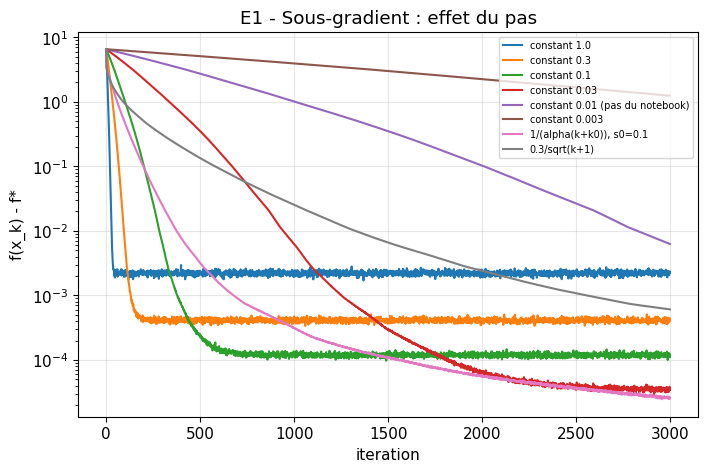

,subopt_k100,subopt_k1000,subopt_finale_med,subopt_finale_max,precision_test
pas,,,,,
constant 1.0,0.002413,0.002446,0.002339,0.003128,0.81800
constant 0.3,0.006006,0.000475,0.000411,0.000511,0.81700
constant 0.1,1.005342,0.000130,0.000115,0.000173,0.81695
constant 0.03,3.932793,0.006246,0.000034,0.000044,0.81685
constant 0.01 (pas du notebook),5.543774,1.010976,0.006266,0.020787,0.81480
constant 0.003,6.221679,3.934652,1.242327,1.995913,0.69705
"1/(alpha(k+k0)), s0=0.1",0.463345,0.000312,0.000026,0.000039,0.81735
0.3/sqrt(k+1),0.930396,0.025271,0.000607,0.001145,0.81790


In [21]:
# E1
cfg = {'constant 1.0': 1.0, 'constant 0.3': 0.3, 'constant 0.1': 0.1, 'constant 0.03': 0.03, 'constant 0.01 (pas du notebook)': 0.01, 'constant 0.003': 0.003,
       '1/(alpha(k+k0)), s0=0.1': (lambda k: 1 / (ALPHA * (k + 1 / (ALPHA * 0.1)))), '0.3/sqrt(k+1)': (lambda k: 0.3 / np.sqrt(k + 1))}
rows = []; plt.figure(figsize=(8, 5))
with np.errstate(all='ignore'):
    for name, st in cfg.items():
        Cc, acc_t = [], []
        for d in data:
            proj = R_BALL if name.startswith(('1/', '0.3/')) else None
            w, fs, _, acc = run_subgradient(d['A'], d['y'], ALPHA, d['w0'], 3000, st, At=d['At'], yt=d['yt'], eval_every=3000, project_R=proj)
            Cc.append(np.maximum(fs - d['fstar'], 1e-16)); acc_t.append(acc[-1, 2])
        Cc = np.array(Cc)
        rows.append(dict(pas=name, subopt_k100=np.median(Cc[:, 100]), subopt_k1000=np.median(Cc[:, 1000]), subopt_finale_med=np.median(Cc[:, -1]), subopt_finale_max=np.max(Cc[:, -1]), precision_test=np.median(acc_t)))
        if np.all(np.isfinite(Cc)): plt.plot(np.median(Cc, axis=0), label=name)
plt.yscale('log'); plt.xlabel('iteration'); plt.ylabel('f(x_k) - f*'); plt.title('E1 - Sous-gradient : effet du pas'); plt.legend(fontsize=7); plt.show()
pd.DataFrame(rows).set_index('pas')

> **Résultats mesurés** (médiane sur 10 instances, 3000 itérations, f − f\*). Pas constants : 1,0 → 2,3·10⁻³ ; 0,3 → 4,1·10⁻⁴ ; 0,1 → 1,2·10⁻⁴ ; 0,03 → 3,4·10⁻⁵ ; **0,01 (pas du notebook) → 6,3·10⁻³** ; 0,003 → **1,2** (non convergé, précision de test 0,70). Pas décroissant 1/(α(k+k₀)) : **2,6·10⁻⁵** (le meilleur) ; 0,3/√(k+1) : 6,1·10⁻⁴. Le maximum sur les 10 instances reste proche de la médiane (par exemple 3,9·10⁻⁵ pour le pas décroissant) : le résultat ne dépend pas d'une instance chanceuse. À k = 100, le pas 1,0 est déjà à 2,4·10⁻³ alors que le pas 0,01 est à 5,5. La précision de test est de 0,817 à 0,818 pour tous les réglages convergés.


> **Interprétation.** Le problème est fortement convexe : pour une fonction lisse α-fortement convexe, f − f\* se contracte d'environ (1 − αs)²ᵏ (complément), soit un gain d'un facteur 1000 en ≈ ln(10³)/(2αs) itérations : ≈ 7 000 pour s = 0,01 et ≈ 700 pour s = 0,1. Le tableau va dans ce sens : entre k = 100 et k = 1000, le pas 0,1 gagne un facteur ≈ 7 700 (prévu : e⁹ ≈ 8 100) et le pas 0,01 un facteur 5,5 (prévu : ≈ 2,5, même ordre de grandeur). La formule vient du cas lisse ; ici je ne fais que constater qu'elle décrit bien les mesures. Les pas constants s'arrêtent sur un **plancher** qui diminue avec le pas (2,3·10⁻³ pour 1,0, 4·10⁻⁴ pour 0,3) ; le pas décroissant supprime ce plancher et donne le meilleur résultat final. Aucun pas testé (jusqu'à 1) ne diverge ; je n'ai pas testé de pas plus grands, donc je ne connais pas le seuil.


> **Contraste avec le LASSO.** Pour le LASSO, le problème venait d'un plateau élevé (oscillations du signe) et d'une faible convergence ; ici la méthode du sous-gradient atteint 3·10⁻⁵ à 4·10⁻⁴ avec les bons pas. Hypothèse, non testée : avec 1000 points, la moyenne de la perte charnière varie de façon presque lisse, donc les « coudes » individuels sont lissés. La forte convexité (α > 0) donne en outre une convergence plus régulière.


> **Limite.** Pas de seuil de stabilité mesuré ; 3000 itérations ; la précision de test est identique à ± 0,001 (incertitude de mesure ≈ 0,004), donc la précision ne discrimine pas ces réglages : seule la valeur de l'objectif le fait.

## E2. Sous-gradient, moyennage, pas décroissant et méthode duale (SDCA)

**Méthodes comparées, à même budget de passes sur les données (*époques*)** : sous-gradient constant 0,1 ; pas décroissant 1/(α(k+k₀)) ; pas décroissant + moyenne de la seconde moitié des itérés ; SDCA (1 époque = m mises à jour de coordonnées duales = le même nombre de produits scalaires qu'un gradient complet).

**Métriques :** f − f*, nombre d'époques pour atteindre 10⁻³ et 10⁻⁶, précision de test finale, écart de dualité (SDCA).

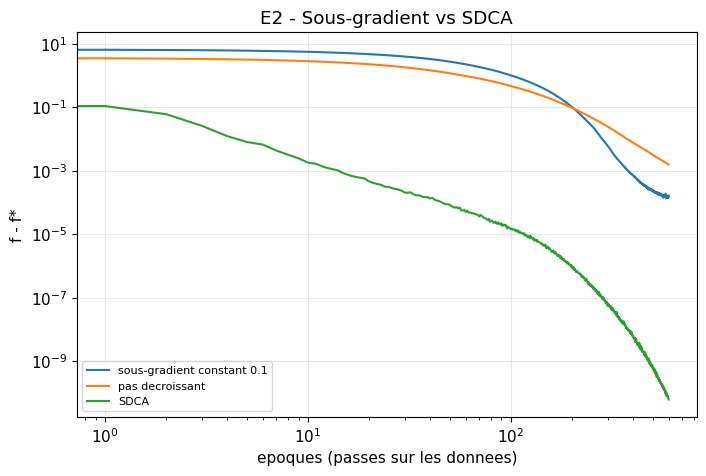

ecart de dualite SDCA final (mediane) : 6.2e-11


,subopt_finale,epoques_1e_3,epoques_1e_6,precision_test
methode,,,,
sous-gradient constant 0.1,1.636995e-04,378,jamais,0.81760
pas decroissant,1.553186e-03,jamais,jamais,0.81735
pas decroissant + moyenne (2e moitie),6.373813e-03,-,-,0.81645
SDCA,6.115525e-11,15,198,0.81675


In [22]:
# E2
EP = 600     # budget d'epoques pour toutes les methodes (3000 pour le sous-gradient complet dans E1 ; ici 600 pour comparer avec SDCA)
dec = lambda k: 1 / (ALPHA * (k + 1 / (ALPHA * 0.1)))
names2 = ['sous-gradient constant 0.1', 'pas decroissant', 'pas decroissant + moyenne (2e moitie)', 'SDCA']
res2 = {k: dict(C=[], acc=[], gap=[]) for k in names2}
for d in data:
    w1, f1, _, a1 = run_subgradient(d['A'], d['y'], ALPHA, d['w0'], EP, 0.1, At=d['At'], yt=d['yt'], eval_every=EP)
    w2, f2, wav, a2 = run_subgradient(d['A'], d['y'], ALPHA, d['w0'], EP, dec, At=d['At'], yt=d['yt'], eval_every=EP, project_R=R_BALL)
    ws, as_, hs = sdca(d['A'], d['y'], ALPHA, EP, np.random.default_rng(1))
    fav = svm_obj(d['A'], d['y'], wav, ALPHA)
    for nm, fs, acc in [(names2[0], f1, a1[-1, 2]), (names2[1], f2, a2[-1, 2]), (names2[3], np.r_[svm_obj(d['A'], d['y'], np.zeros(100), ALPHA), hs[:, 0]], accuracy(d['At'], d['yt'], ws))]:
        res2[nm]['C'].append(np.maximum(fs - d['fstar'], 1e-16)); res2[nm]['acc'].append(acc)
    # moyenne : on ne l'a qu'a la fin -> une seule valeur ; on la reporte comme valeur finale
    res2[names2[2]]['C'].append(np.maximum(np.r_[np.full(EP, np.nan), fav - d['fstar']], 1e-16)); res2[names2[2]]['acc'].append(accuracy(d['At'], d['yt'], wav))
    res2['SDCA']['gap'].append(hs[-1, 1])
plt.figure(figsize=(8, 5)); rows = []
for nm in names2:
    Cc = np.array(res2[nm]['C'])
    if nm != names2[2]: plt.plot(np.median(Cc, axis=0), label=nm)
    def first(tol):
        idx = np.where(np.median(Cc, axis=0) < tol)[0]; return int(idx[0]) if len(idx) else 'jamais'
    rows.append(dict(methode=nm, subopt_finale=np.nanmedian(Cc[:, -1]), epoques_1e_3=first(1e-3) if nm != names2[2] else '-', epoques_1e_6=first(1e-6) if nm != names2[2] else '-', precision_test=np.median(res2[nm]['acc'])))
plt.xscale('log'); plt.yscale('log'); plt.xlabel('epoques (passes sur les donnees)'); plt.ylabel('f - f*'); plt.title('E2 - Sous-gradient vs SDCA'); plt.legend(fontsize=8); plt.show()
print("ecart de dualite SDCA final (mediane) : %.1e" % np.median(res2['SDCA']['gap']))
pd.DataFrame(rows).set_index('methode')

> **Résultats mesurés** (médiane, 600 époques). Époques pour atteindre f − f\* < 10⁻³ : sous-gradient constant 0,1 → **378** ; pas décroissant → jamais (1,6·10⁻³ à 600) ; **SDCA → 15**. Pour 10⁻⁶ : SDCA → **198**, les sous-gradients jamais. À la fin : SDCA 6·10⁻¹¹ (écart de dualité 6·10⁻¹¹), sous-gradient constant 1,6·10⁻⁴ (son plancher), moyenne de la seconde moitié du pas décroissant 6,4·10⁻³. Précision de test : 0,816 à 0,818 pour toutes les méthodes.

> **Interprétation.** SDCA fait une mise à jour **exacte** par coordonnée duale (une formule fermée avec un écrêtage dans [0,1]) : il n'y a aucun pas à régler, la décroissance est linéaire et le critère d'arrêt est certifié par l'écart de dualité. Il tire parti de la forte convexité et de la structure « perte charnière + ℓ2 » (notes EE227C). Le sous-gradient ne suit que la direction d'un sous-gradient, sans tirer parti de la structure, et sa phase finale est lente.


> **Moyennage.** Contrairement à la cellule du notebook, la moyenne de la seconde moitié est **moins bonne** que le dernier itéré du pas décroissant (6,4·10⁻³ contre 1,6·10⁻³) : tant que les itérés sont encore en train
 de converger, la moyenne contient des points anciens et moins bons.


> **Critique et limites.**
- (1) La comparaison est à nombre d'époques égal ; une mise à jour SDCA et un gradient complet coûtent le même ordre de calcul (O(mn)), mais mon SDCA est écrit avec une boucle Python, donc les temps ne sont pas comparables.
- (2) SDCA est spécifique à ce type de problème (et plus lent quand α est petit, voir E4).
-  (3) La précision de test n'est pas discriminante : elle est identique pour toutes les méthodes aux incertitudes près.

## E3. Taille du mini-batch (sous-gradient stochastique)
**Idée** (slides du cours, p. 24-26 ; notes EE227C, ch. 10) : un mini-batch de b exemples coûte b/m d'un gradient complet mais bruite la direction.


**Paramètre modifié :** b ∈ {1, 5, 10, 50, 200, 1000} (1000 = m : gradient complet) ;

**budget identique** de 50 époques. Pas décroissant s_k = 1/(α(k + k₀)), k₀ = 1/(α s₀), avec s₀ ∈ {0,03 ; 0,1 ; 0,3 ; 1}, iterés projetés sur la boule de rayon √(2/α). 5 instances.

**Métriques :** f − f*, précision de test, temps.

s0       0.03     0.10     0.30     1.00
b                                       
1    5.66e-03 5.52e-03 5.59e-03 5.61e-03
5    4.11e-03 4.29e-03 4.33e-03 4.34e-03
10   4.21e-03 4.79e-03 5.02e-03 5.01e-03
50   3.01e-02 4.62e-03 5.12e-03 5.26e-03
200  7.21e-01 5.19e-02 4.17e-03 4.27e-03
1000 2.40e+00 1.16e+00 2.21e-01 3.98e-03


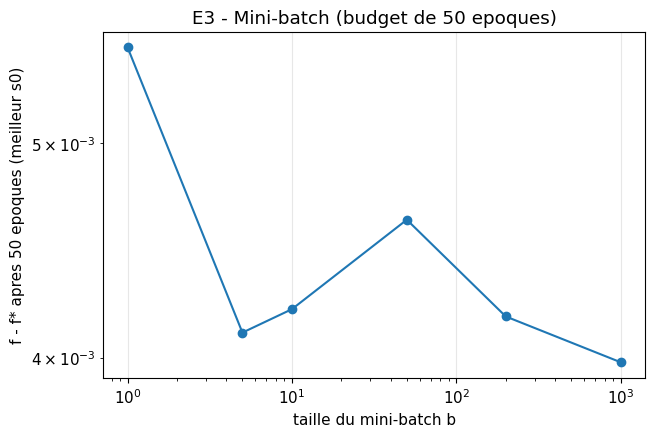

,s0,subopt_mediane,precision_test,temps_s
b,,,,
1,0.10,0.005522,0.8098,2.604409
5,0.03,0.004105,0.8137,0.614202
10,0.03,0.004207,0.8131,0.312623
50,0.10,0.004616,0.8143,0.110208
200,0.30,0.004175,0.8137,0.037772
1000,1.00,0.003981,0.8133,0.011789


In [23]:
# E3
BATCHES, S0S, EPOCHS3 = [1, 5, 10, 50, 200, 1000], [0.03, 0.1, 0.3, 1.0], 50
rows = []
for bsz in BATCHES:
    for s0 in S0S:
        fin, accs, tms = [], [], []
        for d in data[:5]:
            rng = np.random.default_rng(300 + bsz); k0 = 1 / (ALPHA * s0); t = time.time()
            w, fs = run_sgd(d['A'], d['y'], ALPHA, d['w0'], EPOCHS3, bsz, (lambda k, k0=k0: 1 / (ALPHA * (k + k0))), rng, project_R=R_BALL)
            tms.append(time.time() - t); fin.append(fs[-1] - d['fstar']); accs.append(accuracy(d['At'], d['yt'], w))
        rows.append(dict(b=bsz, s0=s0, subopt_mediane=np.median(fin), subopt_max=np.max(fin), precision_test=np.median(accs), temps_s=np.mean(tms)))
df3 = pd.DataFrame(rows)
print(df3.pivot_table(index='b', columns='s0', values='subopt_mediane').to_string(float_format=lambda v: '%.2e' % v))
best = df3.loc[df3.groupby('b').subopt_mediane.idxmin()].set_index('b')[['s0', 'subopt_mediane', 'precision_test', 'temps_s']]
plt.figure(figsize=(7, 4.5)); plt.plot(best.index, best.subopt_mediane, 'o-'); plt.xscale('log'); plt.yscale('log'); plt.xlabel('taille du mini-batch b'); plt.ylabel('f - f* apres 50 epoques (meilleur s0)'); plt.title('E3 - Mini-batch (budget de 50 epoques)'); plt.show()
best

> **Résultats mesurés** (médiane sur 5 instances, 50 époques, meilleur s₀ pour chaque b). f − f\* : b = 1 → 5,5·10⁻³ ; b = 5 → 4,1·10⁻³ ; b = 10 → 4,2·10⁻³ ; b = 50 → 4,6·10⁻³ ; b = 200 → 4,2·10⁻³ ; b = 1000 (gradient complet) → **4,0·10⁻³**. Le **meilleur s₀ augmente avec b** : 0,03 (b = 5, 10), 0,1 (b = 50), 0,3 (b = 200), 1,0 (b = 1000). Précision de test : 0,810 à 0,814 pour toutes les tailles. Temps de calcul : environ 1 s pour b = 1 contre quelques millisecondes pour le gradient complet.


> **Interprétation.** À budget de données égal (50 époques), **la taille du batch ne change presque pas la précision atteinte**. Ce qui change, c'est le pas admissible : plus le batch est petit, plus la direction est bruitée et plus il faut un petit pas (les slides du cours, p. 26, indiquent qu'un mini-lot « réduit le coût par itération mais introduit une variance »). La sensibilité au pas est aussi très différente : pour b = 1 le résultat est presque insensible à s₀ (5,5 à 5,7·10⁻³) parce que le pas décroît de toute façon sur 50 000 itérations, alors que pour b = 1000, un s₀ trop petit empêche de converger en 50 itérations (2,4 pour s₀ = 0,03, contre 4·10⁻³ pour s₀ = 1).


> **Critique et limites.** (1) m = 1000 est petit : le gradient complet coûte quasiment rien en NumPy, donc le gradient stochastique n'a aucun intérêt pratique ici (plus de 100 fois plus lent pour b = 1, à cause de la boucle Python plus que du calcul). Cela ne dit rien de ce qui se passe pour m très grand. (2) Le meilleur s₀ est au bord de la grille pour b = 1000 : un pas plus grand serait peut-être meilleur. (3) Le plateau d'environ 4·10⁻³ est peut-être lié à l'horizon de 50 époques plus qu'au bruit : je ne l'ai pas séparé. (4) Ce réglage de s₀ par taille de batch est un coût de réglage qu'on ne doit pas oublier dans une comparaison honnête.

## E4. Paramètre de régularisation α
**Paramètre modifié :** α ∈ {0,001 ; 0,01 ; 0,05 ; 0,2 ; 1}.

**Constant :** données (5 instances), solution **exacte** par SDCA (écart de dualité < 10⁻⁸).

**Métriques :** précision d'entraînement et de test, ‖w*‖, proportion de points avec marge < 1 (*vecteurs supports*), nombre d'époques SDCA nécessaires, et f − f* du sous-gradient à pas décroissant après 3000 itérations (difficulté d'optimisation).

In [24]:
# E4
rows = []
for al in [0.001, 0.01, 0.05, 0.2, 1.0]:
    tr, te, nw, sv, ep, sg = [], [], [], [], [], []
    for sd in range(5):
        A_i, y_i, At_i, yt_i, rng_i = make_data(sd)
        w_i, a_i, h_i = sdca(A_i, y_i, al, 3000, np.random.default_rng(sd), tol=1e-7)
        tr.append(accuracy(A_i, y_i, w_i)); te.append(accuracy(At_i, yt_i, w_i)); nw.append(np.linalg.norm(w_i)); sv.append(np.mean(y_i * (A_i @ w_i) < 1)); ep.append(len(h_i))
        Rb = np.sqrt(2 / al); k0 = 1 / (al * min(0.1, 1.0)); w0_i = rng_i.normal(0, 1, 100)
        _, fs, _, _ = run_subgradient(A_i, y_i, al, w0_i, 3000, (lambda k, k0=k0, al=al: 1 / (al * (k + k0))), project_R=Rb, eval_every=3000)
        sg.append(fs[-1] - h_i[-1, 0])
    rows.append(dict(alpha=al, precision_train=np.median(tr), precision_test=np.median(te), norme_w=np.median(nw), part_marge_inf_1=np.median(sv), epoques_SDCA=int(np.median(ep)), subopt_sousgradient_3000it=np.median(sg)))
pd.DataFrame(rows).set_index('alpha')

,precision_train,precision_test,norme_w,part_marge_inf_1,epoques_SDCA,subopt_sousgradient_3000it
alpha,,,,,,
0.001,0.873,0.8007,1.909164,0.314,3000,0.000072
0.010,0.873,0.8075,1.707819,0.333,1732,0.000079
0.050,0.867,0.8112,1.280648,0.405,270,0.000026
0.200,0.859,0.8186,0.915456,0.536,86,0.000006
1.000,0.856,0.8245,0.553233,0.791,24,0.000002


> **Résultats mesurés** (médiane sur 5 instances, solution exacte). Plus α augmente, plus la précision de **test** augmente : 0,801 (α = 0,001) → 0,808 → 0,811 (α = 0,05) → 0,819 → **0,825** (α = 1), alors que la précision d'entraînement baisse (0,873 → 0,856). La norme de w\* diminue (1,91 → 0,55) et la proportion de points avec marge < 1 (vecteurs supports) augmente (0,31 → 0,79). Les époques SDCA nécessaires passent de 24 (α = 1) à 86, 270, 1732 et **3000 (plafond atteint, non convergé)** pour α = 0,001.


> **Interprétation.** α règle le compromis **ajustement / généralisation**. Un α faible laisse le SVM coller aux données d'entraînement (précision d'entraînement plus haute, test plus bas : sur-ajustement léger, n = 100 paramètres pour 1000 points). Un α plus grand donne une solution de norme plus faible, plus proche du classifieur par différence des moyennes, ce qui est ici favorable, car les deux classes diffèrent par un petit décalage uniforme sur toutes les coordonnées (hypothèse, cohérente avec le fait que le vecteur de uns atteint 0,84). Le meilleur α testé est le plus grand (1) : l'optimum est peut-être au-delà ; je n'ai pas testé α > 1. En pratique on choisirait α par validation croisée (complément, non fait).


> **Difficulté d'optimisation.** Quand α diminue, la forte convexité diminue et SDCA devient beaucoup plus lent (de 24 à plus de 3000 époques) ; à α = 0,001 la solution de référence n'est donc pas certifiée à 10⁻⁷ (plafond atteint). Le sous-gradient à pas décroissant 1/(α(k+k₀)) reste lui entre 2·10⁻⁶ et 8·10⁻⁵ pour tous les α après 3000 itérations parce que son pas s'adapte à α.

> **Limite.** Précisions de test à ± 0,004 près (10 000 points) : seul l'écart entre extrêmes (0,801 → 0,825) est supérieur à l'incertitude ; les valeurs intermédiaires ne sont pas distinguables deux à deux.

## E5. Initialisation et critère d'arrêt

**(a) Initialisation :** w₀ = 0 contre w₀ ~ N(0, I) (comme dans le notebook), sous-gradient à pas constant 0,1 et à pas décroissant, f − f* après 100 et 3000 itérations (10 instances).

**(b) Critère d'arrêt :** pour SDCA, l'écart de dualité P − D peut-il remplacer f − f* (inconnu en pratique) ? Pour le sous-gradient, la norme du sous-gradient tend-elle vers 0 ?

,"constant 0.1, k=100","constant 0.1, k=3000","decroissant, k=100","decroissant, k=3000"
initialisation,,,,
w0 = 0,0.001416,0.000128,0.002246,0.000009
"w0 ~ N(0,I)",1.005342,0.000115,0.463345,0.000026


SDCA : epoque | f - f* (inconnu en pratique) | ecart de dualite (calculable) | gap >= f-f* ?
     1   |   1.15e-01   |   2.81e-01   |   True
     5   |   7.92e-03   |   1.38e-02   |   True
    10   |   1.38e-03   |   2.19e-03   |   True
    50   |   7.20e-05   |   7.56e-05   |   True
   100   |   1.07e-05   |   1.08e-05   |   True
   200   |   2.89e-07   |   2.89e-07   |   True
   300   |   7.87e-09   |   7.87e-09   |   True


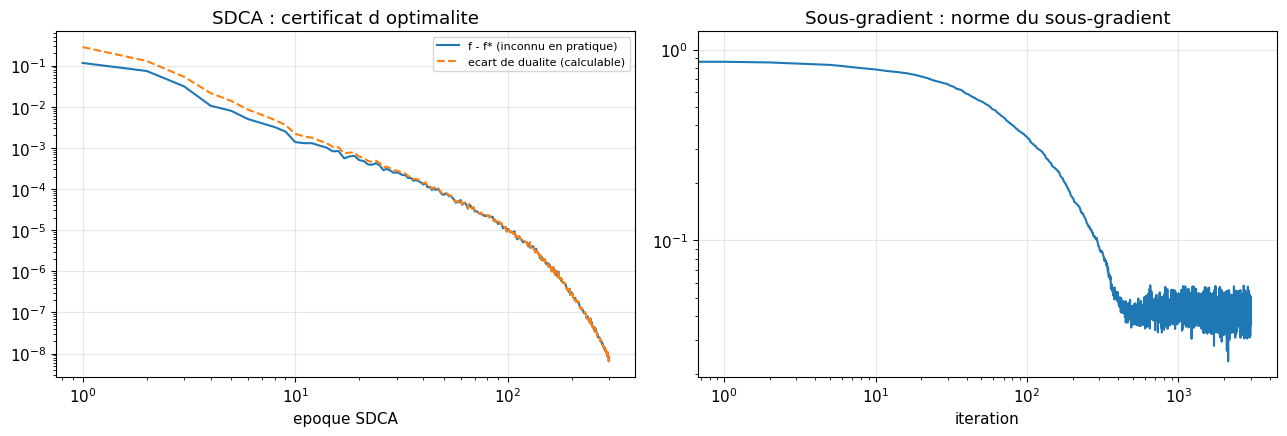

norme du sous-gradient : min = 0.023, derniere valeur = 0.047


In [25]:
# E5
rows = []
for name, init in [('w0 = 0', 'zero'), ('w0 ~ N(0,I)', 'rand')]:
    r = {('constant 0.1', 100): [], ('constant 0.1', 3000): [], ('decroissant', 100): [], ('decroissant', 3000): []}
    for d in data:
        w0_ = np.zeros(100) if init == 'zero' else d['w0']
        _, f1, _, _ = run_subgradient(d['A'], d['y'], ALPHA, w0_, 3000, 0.1, eval_every=3000)
        _, f2, _, _ = run_subgradient(d['A'], d['y'], ALPHA, w0_, 3000, dec, eval_every=3000, project_R=R_BALL)
        for key, f in [(('constant 0.1', 100), f1[100]), (('constant 0.1', 3000), f1[-1]), (('decroissant', 100), f2[100]), (('decroissant', 3000), f2[-1])]:
            r[key].append(max(f - d['fstar'], 1e-16))
    rows.append(dict(initialisation=name, **{'%s, k=%d' % k: np.median(v) for k, v in r.items()}))
display(pd.DataFrame(rows).set_index('initialisation'))

# (b) critere d'arret
d = data[0]; ws, as_, hs = sdca(d['A'], d['y'], ALPHA, 300, np.random.default_rng(1))
true_sub = hs[:, 0] - d['fstar']; gaps = hs[:, 1]
print("SDCA : epoque | f - f* (inconnu en pratique) | ecart de dualite (calculable) | gap >= f-f* ?")
for ep in [1, 5, 10, 50, 100, 200, 300]:
    print("   %3d   |   %.2e   |   %.2e   |   %s" % (ep, true_sub[ep - 1], gaps[ep - 1], gaps[ep - 1] >= true_sub[ep - 1] - 1e-15))
w = d['w0'].copy(); gn = []
for k in range(3000):
    g = subgrad(d['A'], d['y'], w, ALPHA); gn.append(np.linalg.norm(g)); w = w - dec(k) * g
    nrm = np.linalg.norm(w); w = w * (R_BALL / nrm) if nrm > R_BALL else w
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(np.arange(1, 301), true_sub, label='f - f* (inconnu en pratique)'); ax[0].plot(np.arange(1, 301), gaps, '--', label='ecart de dualite (calculable)'); ax[0].set_yscale('log'); ax[0].set_xscale('log'); ax[0].set_xlabel('epoque SDCA'); ax[0].legend(fontsize=8); ax[0].set_title('SDCA : certificat d optimalite')
ax[1].plot(gn); ax[1].set_yscale('log'); ax[1].set_xscale('log'); ax[1].set_xlabel('iteration'); ax[1].set_title('Sous-gradient : norme du sous-gradient'); plt.tight_layout(); plt.show()
print("norme du sous-gradient : min = %.3f, derniere valeur = %.3f" % (min(gn), gn[-1]))
plt.rcParams.update(OLD_RC)

> **Résultats mesurés.**
- (a) *Initialisation* (médiane sur 10 instances) : à k = 100, f − f\* vaut 1,4·10⁻³ depuis w₀ = 0 contre **1,0** depuis w₀ aléatoire (pas constant 0,1), et 2,2·10⁻³ contre 0,46 pour le pas décroissant. À k = 3000, les deux départs sont équivalents : 1,3·10⁻⁴ et 1,2·10⁻⁴ (constant), 9·10⁻⁶ et 2,6·10⁻⁵ (décroissant).
- (b) *Critère d'arrêt* : l'écart de dualité de SDCA est **toujours supérieur ou égal** à f − f\* (7 points de contrôle sur 7) et devient quasi égal à partir de l'époque 50 (par exemple 1,08·10⁻⁵ contre 1,07·10⁻⁵ à l'époque 100 ; 7,9·10⁻⁹ des deux côtés à l'époque 300). À l'époque 1, il surestime d'un facteur 2,4 (0,28 contre 0,115). La norme du sous-gradient reste petite mais ne s'annule pas : minimum 0,023, valeur finale 0,047.


> **Interprétation.** (a) Le problème est fortement convexe : le minimiseur est unique et l'influence du départ disparaît avec les itérations ; elle ne joue que sur le régime transitoire (100 premières itérations). (b) L'écart de dualité est un **certificat** : s'arrêter quand il est inférieur à ε garantit f − f\* < ε, sans connaître f\*. C'est un avantage décisif de la méthode duale. Pour le sous-gradient, la norme n'est pas nulle ; une borne existe tout de même (complément) : pour une fonction α-fortement convexe et tout sous-gradient g, f(x) − f\* ≤ ‖g‖²/(2α). Ici elle donne environ 0,022 (0,047²/0,1) alors que l'erreur réelle est de l'ordre de 10⁻⁵ : valide mais environ mille fois trop pessimiste.


> **Limite.** Un seul schéma de pas décroissant ; l'instance 0 pour le critère d'arrêt.

---
# Synthèse : applicabilité, fiabilité, limites, améliorations

### Tableau récapitulatif (SVM sans biais, m = 1000, n = 100, α = 0,05, données gaussiennes à classes qui se recouvrent)
| Méthode | Adaptée si… | Fiabilité observée | Critère d'arrêt | Limite principale |
|---|---|---|---|---|
| Sous-gradient du notebook (somme, pas 0,01) | — | **faible** : mal échelonné (α/m effectif), courbe tracée avec un autre α, plateau à 0,43 de l'optimum | aucun | résultats trompeurs, norme 3× trop grande |
| Sous-gradient corrigé, pas constant bien choisi | on veut un code simple | **bonne** : 3·10⁻⁵ à 4·10⁻⁴ avec s ∈ [0,03 ; 0,3] (E1), plancher qui baisse avec s | borne ‖g‖²/(2α), pessimiste | s trop petit : très lent (0,003 → non convergé) |
| Sous-gradient, pas 1/(α(k+k₀)) | α connu, horizon long | **très bonne** : 2,6·10⁻⁵ après 3000 it. | idem | lent en fin de course |
| Mini-batch (b petit) | m très grand (non testé) | sur m = 1000 : aucun gain d'époques (E3) | idem | pas à régler selon b |
| **SDCA (dual)** | perte charnière + ℓ2, α pas trop petit | **excellente** : 6·10⁻¹¹ en médiane (E2) | **écart de dualité, certifié** | lent si α très petit (3000 époques à α = 0,001) |

### Applicabilité
Le problème est convexe, non lisse (perte charnière) et **α-fortement convexe** : le minimiseur existe, est unique, et tout point stationnaire est global. Contrairement au LASSO, la forte convexité est satisfaite : on peut compter sur une convergence régulière du sous-gradient avec un pas bien choisi, et sur la dualité (SDCA). Les données de l'exercice ne sont pas séparables (classes qui se recouvrent) : c'est justement le cas où la perte charnière régularisée est nécessaire (le SVM à marge dure n'aurait pas de solution).

### Fiabilité (ce qu'on peut affirmer et ce qu'on ne peut pas)
* **Affirmé (mesuré) :** SDCA et scikit-learn donnent la même solution à 10⁻¹⁰ près ; la version du notebook minimise en fait un SVM quasi non régularisé avec un pas très grand et ne converge pas (0,43 au-dessus de l'optimum) ; avec le sous-gradient corrigé et un pas bien choisi, on atteint 3·10⁻⁵ à 4·10⁻⁴ ; le pas trop petit est le principal danger ici (le contraire du LASSO) ; la précision de test est insensible à la précision d'optimisation dès que f − f\* < 10⁻² ; α est le levier de la généralisation ; le mini-batch n'apporte rien à m = 1000.
* **Non testé :** données plus grandes ou mieux séparées ; avec biais ; classes déséquilibrées ; autres valeurs de α au-delà de [0,001 ; 1] ; la validation croisée pour choisir α ; la recherche du pas maximal sans divergence ; les méthodes à variance réduite.
* **Niveau de confiance :** élevé pour « le notebook d'origine contient une erreur d'échelle et d'α, et SDCA est plus fiable que le sous-gradient » (vérifié par différences finies, scikit-learn et 10 instances). Moyen pour le mini-batch (5 instances, grille de pas limitée, m petit). La précision de test n'est pas un critère discriminant ici (incertitude ≈ 0,004).

### Amélioration à retenir
**Corriger l'implémentation** (moyenne au lieu de somme, α cohérent, y\*(A@x) au lieu de diag(y)) puis utiliser un **pas décroissant 1/(α(k+k₀))** ou, mieux, **SDCA avec l'écart de dualité comme critère d'arrêt**. L'amélioration est justifiée par des limites *observées* (plateau, absence de certificat), pas par goût de la sophistication.


1. **« Pourquoi un sous-gradient et pas un gradient ? »**

— La perte charnière a un coude en z = 1 : elle n'est pas dérivable. On utilise un élément du sous-différentiel (−1 si z < 1, 0 si z > 1, n'importe quelle valeur de [−1, 0] en z = 1).
2. **« Pourquoi l'objectif est-il fortement convexe ? »**

 — À cause du terme (α/2)‖x‖² ; la perte charnière est seulement convexe. C'est ce qui donne un minimiseur unique et une convergence régulière.
3. **« Quelle erreur avez-vous trouvée dans le notebook ? »**

 — Le sous-gradient somme les m pertes au lieu de les moyenner (facteur m), et la courbe est tracée avec α = 0,1 alors que l'optimisation utilise α = 0,05. Preuve : différences finies et comparaison avec SDCA/scikit-learn.
4. **« Pourquoi SDCA est-il plus fiable ? »**

— Il travaille sur le dual, où chaque coordonnée a une mise à jour exacte en forme fermée, et il fournit un écart de dualité qui majore l'erreur : on sait quand s'arrêter.
5. **« La meilleure valeur de l'objectif donne-t-elle la meilleure précision ? »**

— Non : le vecteur de uns (0,843 au test) fait mieux que le minimiseur exact (0,822 pour α = 0,05) ; et la précision de test augmente avec α jusqu'à 1 (E4).

---
# Sparse Inverse Covariance Estimation et Gradient madness (sections commentées)



## Sparse Inverse Covariance Estimation

Given a positive semidefinite matrix $S\in\mathbb{R}^{n\times n}$ the objective function in sparse inverse covariance estimation is as follows:

<p>
$$ \min_{X\in\mathbb{R}^{n\times n}, X\succeq 0}
\langle S, X\rangle - \log\det(X) + \alpha\|X\|_1$$
</p>

Here, we define
$$\langle S, X\rangle = \mathrm{trace}(S^\top X)$$
and
$$\|X\|_1 = \sum_{ij}|X_{ij}|.$$

Typically, we think of the matrix $S$ as a sample covariance matrix of a set of vectors $a_1,\dots, a_m,$ defined as:
$$
S = \frac1{m-1}\sum_{i=1}^n a_ia_i^\top
$$
The example also highlights the utility of automatic differentiation as provided by the `autograd` package that we'll regularly use. In a later lecture we will understand exactly how automatic differentiation works. For now we just treat it as a blackbox that gives us gradients.

> **Ce que j'ai compris du problème :** on cherche une matrice X (ici 5×5) qui minimise f(X) = ⟨S, X⟩ − log det X + α‖X‖₁, où S est la covariance empirique. Les variables de décision sont les coefficients de X ; la contrainte est que X soit **définie positive**. Sans le terme ℓ1 (α = 0), le gradient S − X⁻¹ s'annule en X = S⁻¹ : l'estimateur est l'inverse de la covariance empirique. Le terme α‖X‖₁ pousse des coefficients de X vers 0, ce qui donne une matrice « creuse ». Dans un modèle gaussien, un zéro de l'inverse de la covariance signifie que deux variables sont indépendantes conditionnellement aux autres .

> **Nature du problème :** ⟨S, X⟩ est linéaire, −log det X est convexe et ℓ1 est convexe : le problème est **convexe**, **non lisse** (ℓ1) et défini sur le cône des matrices définies positives. Comme pour le LASSO, tout minimum local est global.

> **Critique du texte :** (1) la contrainte est écrite X ⪰ 0 (semi-définie), mais −log det X vaut +∞ dès qu'une valeur propre s'annule : le vrai domaine est X ≻ 0 (définie positive). (2) La somme S = (1/(m−1)) Σ_{i=1}^{n} a_i a_iᵀ s'arrête à n alors que les vecteurs sont a_1, …, a_m : c'est une faute de frappe (la somme va jusqu'à m). (3) Dire que S est une covariance empirique suppose des données centrées.

In [26]:

import autograd.numpy as np
from autograd import grad

np.random.seed(1337)

In [27]:
# Objectif : <S, X> - log det(X) + alpha * ||X||_1 (somme des valeurs absolues de TOUS les coefficients, diagonale comprise).
# Attention : np.log(np.linalg.det(X)) est numériquement fragile (le déterminant peut déborder ou valoir 0) ; np.linalg.slogdet est plus stable.
# La diagonale est aussi pénalisée ; dans la pratique on pénalise souvent seulement les coefficients hors diagonale (complément).
def sparse_inv_cov(S, X, alpha=0.1):
    return (np.trace(S.T.dot(X))
            - np.log(np.linalg.det(X))
            + alpha * np.sum(np.abs(X)))

In [28]:
# S = A A^T est une matrice aléatoire semi-définie positive 5x5. Ce n'est PAS la covariance d'un vrai jeu de données :
# il n'y a donc pas de « vraie » matrice creuse à retrouver, et on ne peut pas juger la qualité de la solution.
# Attention : n, A, objective et gradient sont redéfinis ici et écrasent les variables des sections précédentes.
# gradient = grad(objective) : autograd donne ici S - X^{-T} + alpha*signe(X) (avec signe(0) = 0).
n = 5
A = np.random.normal(0, 1, (n, n))
S = A.dot(A.T)
objective = lambda X: sparse_inv_cov(S, X)
# autograd provides a "gradient", yay!
gradient = grad(objective)

> **Ce que j'ai compris :** on veut garder X définie positive. Le notebook fait un pas de gradient puis **projette sur le cône des matrices semi-définies positives** en mettant à 0 les valeurs propres négatives. C'est le gradient projeté du cours (notes EE227C, chap. 2), où l'ensemble admissible est le cône.

In [29]:
# Projection sur le cône semi-défini positif : on met à 0 les valeurs propres négatives.
# !!(1) np.linalg.eig est écrit pour des matrices quelconques ; pour une matrice symétrique, np.linalg.eigh est mieux adapté (valeurs propres réelles, vecteurs orthonormés).
# !!(2) On projette sur le cône SEMI-défini (valeurs propres >= 0), alors que log det exige des valeurs propres STRICTEMENT positives.
def projection(X):
    """Projection onto positive semidefinite cone."""
    es, U = np.linalg.eig(X)
    es[es<0] = 0.
    return U.dot(np.diag(es).dot(U.T))

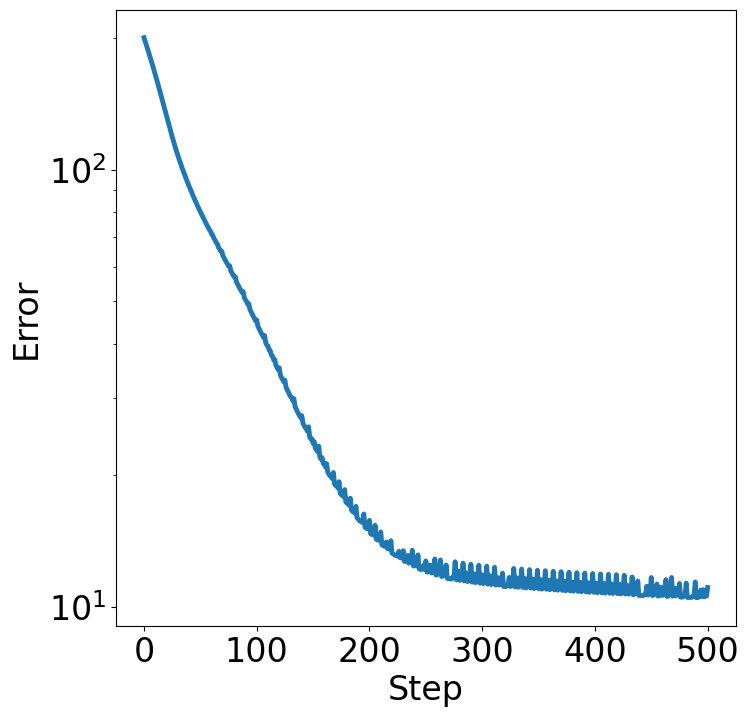

In [30]:
# Gradient projeté, pas constant 0.01, 500 itérations, départ X0 = A0 A0^T aléatoire.
#!!(a) la courbe est la valeur de l'objectif f(X_k), et non f(X_k) - f* : on n'a aucune solution de référence ;
# !!(b) il n'y a aucun critère d'arrêt ;!! (c) le terme ℓ1 est traité par un sous-gradient, comme dans la première version du LASSO.
A0 = np.random.normal(0, 1, (n,n))
X0 = A0.dot(A0.T)
Xs = gradient_descent(X0, [0.01]*500, gradient, projection)
error_plot([objective(X) for X in Xs])

> **Interprétation de la figure (sortie d'origine) :** d'après la figure, l'objectif passe d'environ 200 à environ 10,5 en ≈ 250 itérations, puis ne descend plus : il oscille en dents de scie entre ≈ 10,5 et ≈ 12 jusqu'à l'itération 500. C'est le même type de comportement que le sous-gradient à pas constant pour le LASSO (plateau avec oscillations), ce que j'attribue à la non-différentiabilité de ℓ1 avec un pas constant. C'est une hypothèse : je n'ai pas testé de pas plus petit ni de pas décroissant sur cette section.
> **Critique :**
> 1. **Pas de référence :** sans solution de référence, on ne sait pas si 10,5 est proche du minimum. La courbe ne prouve pas la convergence.
> 2. **Lissité :** le terme −log det X a un gradient −X⁻¹ qui n'est **pas Lipschitz** sur tout le domaine (il explose quand une valeur propre tend vers 0). L'hypothèse « fonction lisse » des théorèmes du cours (notes EE227C, chap. 2) n'est donc vraie que sur les ensembles où X reste loin du bord, et un pas constant n'est justifié que là.
> 3. **Domaine :** le pas de gradient peut sortir du domaine défini positif ; la projection sur le cône semi-défini ne garantit pas la stricte positivité (voir le commentaire dans le code). Avec le pas 0,01 la courbe reste finie, mais ce n'est pas garanti en général.
> 4. **Données :** S est aléatoire, sans structure creuse sous-jacente ; on ne mesure donc pas la capacité de l'ℓ1 à retrouver les zéros, qui est le but de la méthode.
> **Alternative :** comme pour le LASSO, le terme ℓ1 se traite mieux par son opérateur proximal (seuillage doux, cours p. 120-123 et 132) plutôt que par un sous-gradient ; il faut en plus maintenir X définie positive. Il existe des algorithmes spécialisés pour ce problème (graphical lasso, complément), que je n'ai pas étudiés ici.
>  ce problème a la même structure que le LASSO (lisse + ℓ1, ici avec un cône en plus). Le sous-gradient à pas constant donne un plateau ; la méthode proximale est la bonne approche. Je n'ai pas vérifié ce second point sur cette section.

<a id="madness"></a>

# Going crazy with autograd

Just for fun, we'll go through a crazy example below. We can use `autograd` not just for getting gradients for natural objectives, we can in principle also use it to tune hyperparameters of our optimizer, like the step size schedulde.

Below we see how we can find a better 10-step learning rate schedules for optimizing a quadratic. This is mostly just for illustrative purposes (although some researchers are exploring these kinds of ideas more seriously).

> **Ce que j'ai compris :** on peut utiliser la dérivation automatique pour régler les hyperparamètres de l'algorithme lui-même, ici la suite des pas d'une descente de gradient. Voyons ce que l'on dérive. Pour f(x) = ½‖x‖², ∇f(x) = x, donc un pas donne x_{k+1} = (1 − s_k) x_k, et après K pas

> f(x_K) = ½‖x₀‖² · ∏_k (1 − s_k)².

> La fonction `optimizer(steps)` est donc ce produit. C'est le résultat du cours sur la quadratique (pas 1 ⇒ minimum en une itération, dans la section d'échauffement) vu comme une fonction des pas.

> **Critique du texte :** le texte dit que `optimizer` est « une fonction non dérivable de ses pas ». Ce n'est pas exact ici : c'est un polynôme en s₁, …, s_K, donc parfaitement dérivable. Ce qu'autograd fait, c'est dériver à travers la boucle du gradient (elle est « déroulée »). Le point intéressant est que cela marche sur un programme avec une boucle, pas que la fonction serait non dérivable.

In [31]:
x0 = np.random.normal(0, 1, 1000)

In [32]:
# optimizer(steps) = f(x_K) après K pas de gradient avec les pas `steps`.
# Comme grad f(x) = x : x_{k+1} = (1 - s_k) x_k, donc f(x_K) = 1/2 ||x0||^2 * produit_k (1 - s_k)^2.
# !! x0 est une variable GLOBALE (définie dans la cellule précédente) ; la fonction en dépend sans que cela apparaisse dans ses arguments.
def f(x):
    return 0.5*np.dot(x,x)

def optimizer(steps):
    """Optimize a quadratic with the given steps."""
    xs = gradient_descent(x0, steps, grad(f))
    return f(xs[-1])

The function `optimizer` is a non-differentiable function of its input `steps`. Nontheless, `autograd` will provide a gradient that we can stick into gradient descent. That is, we're tuning gradient descent with gradient descent.

In [33]:
grad_optimizer = grad(optimizer)

In [34]:
# Descente de gradient sur les pas eux-mêmes (méta-optimisation) : pas 0.001, 500 itérations, départ = 10 pas aléatoires |N(0, 0.1)|.
# D'après la formule ci-dessus, la dérivée de f(x_K) par rapport à s_i vaut -2 f(x_K) / (1 - s_i) : elle est proportionnelle à f(x_K).
initial_steps = np.abs(np.random.normal(0, 0.1, 10))
better_steps = gradient_descent(initial_steps, [0.001]*500, grad_optimizer)

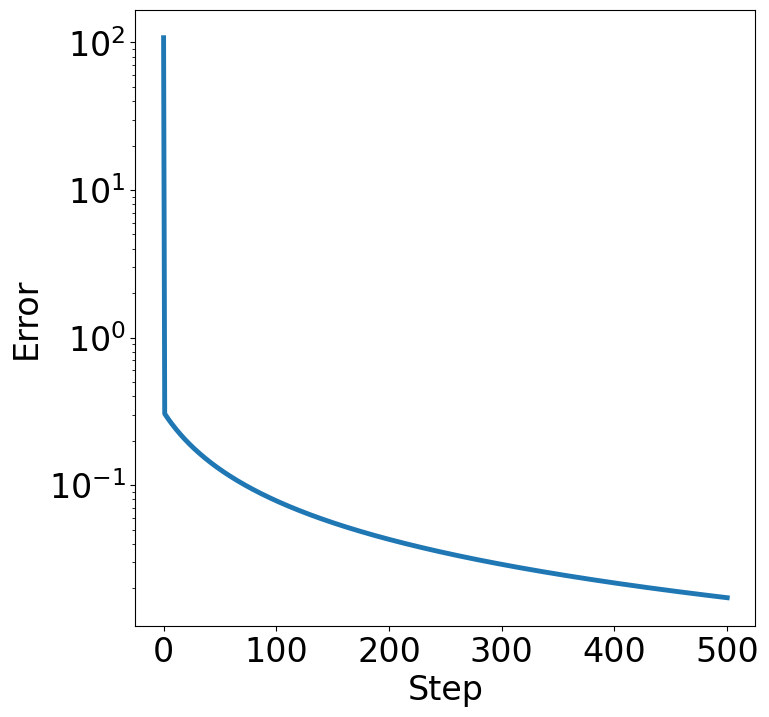

In [35]:
error_plot([optimizer(steps) for steps in better_steps])

> **Interprétation (figure d'origine) :** la valeur f(x₁₀) passe d'environ 110 à environ 0,017 en 500 itérations de la méta-descente : elle chute très vite au début puis décroît lentement. Cela correspond à la formule : comme la dérivée par rapport à chaque pas est proportionnelle à f, la méta-descente ralentit quand f devient petite (explication par le calcul, non testée par une autre expérience).

As we can see, the learning rate schedules improve dramatically over time. Of course, we already know from the first example that there is a step size schedule that converges in one step. Interestingly, the last schedule we find here doesn't look at all like what we might expect:

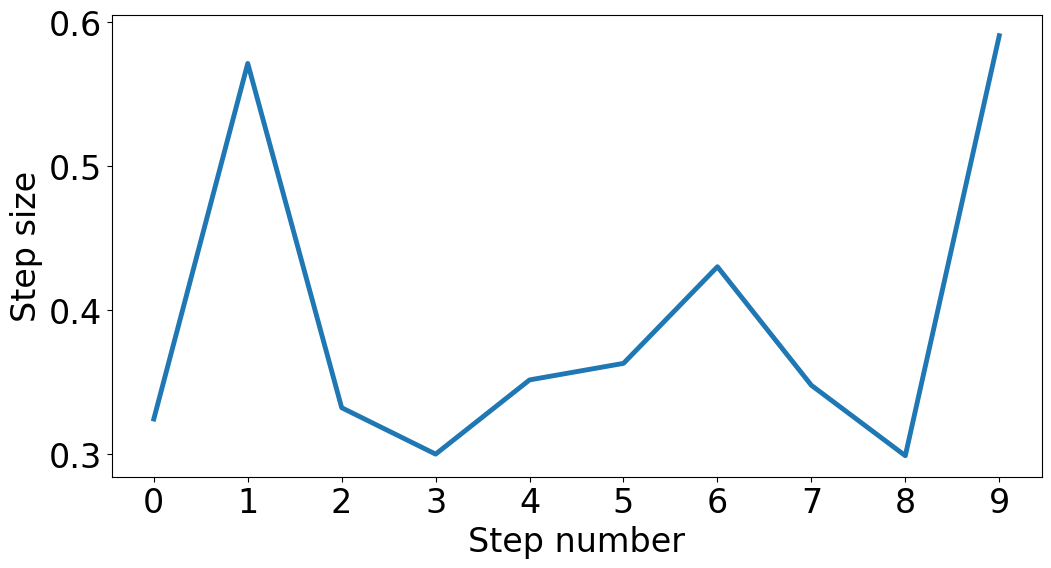

In [36]:
plt.figure(figsize=(12,6))
plt.xticks(range(len(better_steps[-1])))
plt.ylabel('Step size')
plt.xlabel('Step number')
plt.plot(range(len(better_steps[-1])), better_steps[-1], **kwargs)

> **Ce que j'ai compris du dernier graphique :** le texte dit que le dernier schéma de pas « ne ressemble pas à ce qu'on attendrait ». Avec la formule f(x₁₀) = ½‖x₀‖² ∏(1 − s_k)², cela s'explique :
> - **l'ordre des pas n'a aucune importance** (le produit est le même quel que soit l'ordre), donc le schéma obtenu n'a pas de structure particulière ;
> - **il n'y a pas de solution unique** : tout schéma qui rend le produit petit convient, y compris ceux où un pas vaut 1 (f = 0 exactement, comme dans la section d'échauffement).
> Vérification à la main : en lisant les pas sur la figure (≈ 0,32 ; 0,57 ; 0,33 ; 0,30 ; 0,35 ; 0,36 ; 0,43 ; 0,35 ; 0,30 ; 0,59, lecture approximative à ±0,01), le produit ∏(1 − s_k)² vaut ≈ 3,7·10⁻⁵ ; avec ½‖x₀‖² ≈ 500 (vecteur gaussien de dimension 1000), on obtient f ≈ 0,018, ce qui est cohérent avec la valeur finale 0,017 de la courbe.
> **Critique :**
> 1. C'est un exemple jouet : la bonne réponse (pas 1) est connue d'avance, ce qui rend la méta-optimisation inutile ici. C'est une illustration, pas une méthode pratique.
> 2. Dériver à travers K itérations demande de mémoriser tout le calcul (mémoire proportionnelle à K) ; sur de vrais problèmes, on ne règle ainsi que très peu d'hyperparamètres, et le problème en les pas n'est en général pas convexe.
> 3. Rien n'empêche des pas négatifs ou supérieurs à 2 (|1 − s| > 1 ferait diverger l'itération) ; on les évite ici parce que la méta-descente part de pas dans [0, 0,3] environ avec un petit pas 0,001.
> 4. Le pas 0,001 et les 500 itérations sont choisis à la main ; je n'ai pas fait varier ces réglages.
> la dérivation automatique donne le gradient exact d'un programme, y compris par rapport aux hyperparamètres. Ici elle retrouve un résultat que l'on sait faire à la main, ce qui permet de la valider.

## That's it for today.